# Notebook 09B: Reusable Cross-Model Visualization and Ideal-TQ Envelope

**CPU-only, Google Drive independent, derived visualization.** This notebook downloads the project ZIP with `gdown`, reads the immutable provisional synthesis bundle with fingerprint `b19adce0924b4203`, and writes a separate visualization bundle under `/content/CSE407_cross_model_visualization_v1/`.

It distinguishes three evidence tiers:

1. **Measured systems:** FP16, AWQ, eviction, and the numerically active TQ-Ref path.
2. **Realized TQ-Ref storage:** uint8 indices, materialized K/V, and unfused execution.
3. **Ideal packed/fused envelope:** analytical persistent-KV and logical byte-demand projections only.

No numerical ideal energy, latency, throughput, power, or peak-VRAM claim is made because the accepted artifacts do not identify fused-kernel compute overhead or joules per avoided byte.

In [2]:
# Run 0: Download the uploaded project ZIP and locate the provisional synthesis bundle
%pip -q install gdown

from pathlib import Path
import hashlib
import json
import math
import shutil
import zipfile

import gdown
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

DRIVE_FILE_ID = "1MtCVx8ZkSVVgQ6Q1SNNEOMnrqvh393O4"
ZIP_PATH = Path("/content/cse407_project.zip")
EXTRACT_ROOT = Path("/content/cse407_uploaded_repo")
OUTPUT_ROOT = Path("/content/CSE407_cross_model_visualization_v1")

if OUTPUT_ROOT.exists():
    raise FileExistsError(f"Fail-closed output already exists: {OUTPUT_ROOT}")
if not ZIP_PATH.exists():
    downloaded = gdown.download(id=DRIVE_FILE_ID, output=str(ZIP_PATH), quiet=False)
    if downloaded is None:
        raise RuntimeError("gdown could not download the project ZIP")
if EXTRACT_ROOT.exists():
    shutil.rmtree(EXTRACT_ROOT)
EXTRACT_ROOT.mkdir(parents=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    unsafe = [name for name in archive.namelist() if Path(name).is_absolute() or ".." in Path(name).parts]
    if unsafe:
        raise RuntimeError(f"Unsafe ZIP members: {unsafe[:5]}")
    archive.extractall(EXTRACT_ROOT)

matches = [
    path for path in EXTRACT_ROOT.rglob("CSE407_cross_model_synthesis_local_provisional")
    if path.is_dir() and (path / "final_integrity.json").is_file()
]
if len(matches) != 1:
    raise RuntimeError(f"Expected one provisional synthesis bundle, found {matches}")
SOURCE = matches[0].resolve()
OUTPUT_ROOT.mkdir(parents=True)

print(f"ZIP: {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Read-only source: {SOURCE}")
print(f"Isolated output: {OUTPUT_ROOT}")

Downloading...
From (original): https://drive.google.com/uc?id=1MtCVx8ZkSVVgQ6Q1SNNEOMnrqvh393O4
From (redirected): https://drive.google.com/uc?id=1MtCVx8ZkSVVgQ6Q1SNNEOMnrqvh393O4&confirm=t&uuid=54e3a0ea-9dee-46ec-af73-3375e596d311
To: /content/cse407_project.zip
100%|██████████| 60.2M/60.2M [00:00<00:00, 101MB/s] 


ZIP: /content/cse407_project.zip (60.2 MB)
Read-only source: /content/cse407_uploaded_repo/Project/evidence/provisional/bundles/CSE407_cross_model_synthesis_local_provisional
Isolated output: /content/CSE407_cross_model_visualization_v1


## Run 1: Fail-Closed Source Validation

The provisional synthesis is used as a read-only derived source. Every manifest-listed file is checked by byte size and SHA-256 before any plot is generated. The source remains provisional; this visualization run does not promote it to accepted experimental evidence.

In [4]:
# Run 1: Validate fingerprint, manifest, hashes, and exact table schemas/counts
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

integrity = json.loads((SOURCE / "final_integrity.json").read_text(encoding="utf-8"))
manifest = json.loads((SOURCE / "output_manifest.json").read_text(encoding="utf-8"))
assert integrity["passed"] is True
assert integrity["fingerprint"] == "b19adce0924b4203"
assert integrity["schema_version"] == "cse407-cross-model-synthesis-v1-2026-08-05-1"
assert sha256_file(SOURCE / "output_manifest.json") == integrity["output_manifest_sha256"]

for item in manifest["files"]:
    path = SOURCE / item["path"]
    assert path.is_file(), item["path"]
    assert path.stat().st_size == item["bytes"], item["path"]
    assert sha256_file(path) == item["sha256"], item["path"]

energy = pd.read_csv(SOURCE / "normalized_energy_rows.csv")
quality = pd.read_csv(SOURCE / "quality_wilson_intervals.csv")
storage = pd.read_csv(SOURCE / "measured_realized_ideal_storage.csv")
ideal = pd.read_csv(SOURCE / "ideal_packed_kv_footprint.csv")
demand = pd.read_csv(SOURCE / "modeled_phase_byte_demand.csv")
break_even = pd.read_csv(SOURCE / "energy_break_even_surface.csv")
inferential = pd.read_csv(SOURCE / "registered_inferential_tests.csv")
empirical_pareto = pd.read_csv(SOURCE / "empirical_pareto.csv")

expected_rows = {
    "energy": 585,
    "quality": 43,
    "storage": 18,
    "ideal": 26,
    "demand": 39,
    "break_even": 81,
    "inferential": 120,
    "empirical_pareto": 10,
}
actual_rows = {name: len(frame) for name, frame in {
    "energy": energy, "quality": quality, "storage": storage,
    "ideal": ideal, "demand": demand, "break_even": break_even,
    "inferential": inferential, "empirical_pareto": empirical_pareto,
}.items()}
assert actual_rows == expected_rows, actual_rows
assert not energy.duplicated(["model", "source_variant", "context", "block", "source_table", "regime"]).any()
assert np.allclose(energy["total_energy_j"], energy["prefill_energy_j"] + energy["decode_energy_j"])
assert np.allclose(quality["estimate"], quality["successes"] / quality["n"])
assert ((quality["wilson95_low"] >= 0) & (quality["wilson95_high"] <= 1)).all()
assert ideal["persistent_memory_dominance_proved"].astype(str).str.lower().eq("true").all()

SOURCE_SNAPSHOT = {
    str(path.relative_to(SOURCE)): sha256_file(path)
    for path in sorted(SOURCE.rglob("*")) if path.is_file()
}
print(json.dumps({
    "source_fingerprint": integrity["fingerprint"],
    "manifest_files_verified": len(manifest["files"]),
    "tables": actual_rows,
    "source_files_snapshotted": len(SOURCE_SNAPSHOT),
}, indent=2))

{
  "source_fingerprint": "b19adce0924b4203",
  "manifest_files_verified": 39,
  "tables": {
    "energy": 585,
    "quality": 43,
    "storage": 18,
    "ideal": 26,
    "demand": 39,
    "break_even": 81,
    "inferential": 120,
    "empirical_pareto": 10
  },
  "source_files_snapshotted": 41
}


## Run 2: Reusable Plotting Contract

Figures use consistent semantic colors across models. Filled marks denote measured or realized-reference values; hollow or hatched marks denote analytical ideal values. Every figure is exported as 300-dpi PNG and vector PDF.

In [5]:
# Run 2: Plot style, semantic labels, and deterministic figure writer
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

MODEL_LABEL = {"llama": "Llama 3.2-3B", "qwen": "Qwen2.5-3B"}
ROLE_COLORS = {
    "FP16": "#264653",
    "AWQ": "#457B9D",
    "Eviction": "#2A9D8F",
    "TQ-Ref": "#E76F51",
    "Eviction + TQ-Ref": "#9B5DE5",
}
VARIANT_ROLE = {
    "llama": {"C0": "FP16", "C1": "AWQ", "C2": "Eviction", "C3": "TQ-Ref", "C4": "Eviction + TQ-Ref"},
    "qwen": {"Q0": "FP16", "Q1-W": "AWQ", "Q2": "Eviction", "Q3-Ref": "TQ-Ref", "Q4-Ref": "Eviction + TQ-Ref"},
}
TQ_PAIRS = {
    "llama": {"TQ-only": ("C1", "C3"), "Eviction + TQ": ("C2", "C4")},
    "qwen": {"TQ-only": ("Q1-W", "Q3-Ref"), "Eviction + TQ": ("Q2", "Q4-Ref")},
}
FIGURES = []

def save_figure(fig, stem, caption):
    fig.suptitle(fig._suptitle.get_text() if fig._suptitle else "", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0.025, 1, 0.965))
    png = OUTPUT_ROOT / f"{stem}.png"
    pdf = OUTPUT_ROOT / f"{stem}.pdf"
    fig.savefig(png, bbox_inches="tight", metadata={"Description": caption})
    fig.savefig(pdf, bbox_inches="tight", metadata={"Subject": caption})
    FIGURES.append({"stem": stem, "caption": caption, "png": png.name, "pdf": pdf.name})
    plt.show()

print("Reusable style and semantic mappings loaded")

Reusable style and semantic mappings loaded


## Run 3: Measured TQ-Ref Overhead

This figure directly answers how much the accessible numerical TQ-Ref path adds relative to its corresponding non-TQ path. It shows paired block-level percentage changes for prefill, decode, and total energy. These are measured reference-path costs, not estimates of a packed kernel.

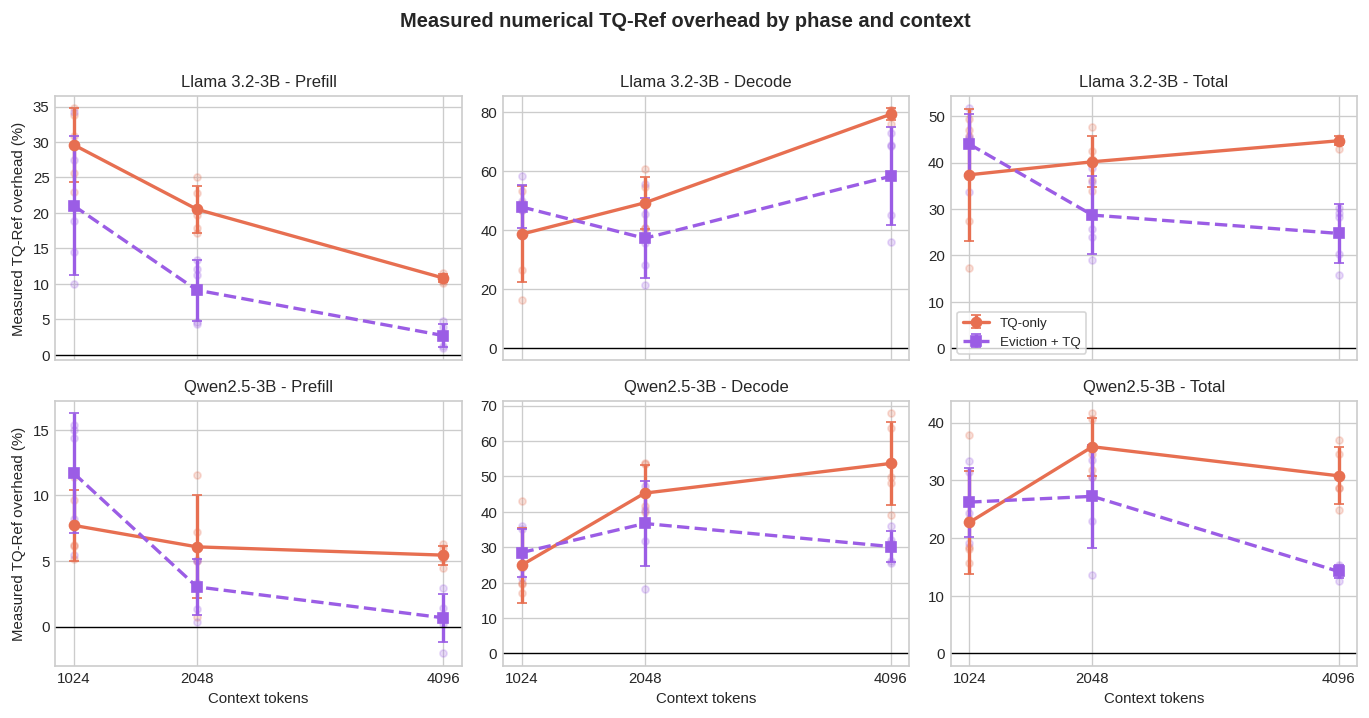

model  pair           context  phase  
qwen   Eviction + TQ  4096     Decode     30.19
                               Prefill     0.67
                               Total      14.22
       TQ-only        1024     Decode     24.94
                               Prefill     7.71
                               Total      22.70
                      2048     Decode     45.29
                               Prefill     6.08
                               Total      35.83
                      4096     Decode     53.68
                               Prefill     5.45
                               Total      30.79
Name: overhead_pct, dtype: float64


In [6]:
# Run 3: Figure 1 - measured incremental TQ-Ref energy overhead
core_raw = energy[
    (energy["source_table"] == "core")
    & (energy["regime"] == "raw")
    & (energy["average_budget"] == 1024)
    & (energy["tq_bits"] == 4)
    & energy["structural_pass"].astype(str).str.lower().eq("true")
].copy()

phase_columns = {
    "Prefill": "prefill_energy_j",
    "Decode": "decode_energy_j",
    "Total": "total_energy_j",
}
overhead_records = []
for model, pairs in TQ_PAIRS.items():
    for pair_name, (baseline_variant, tq_variant) in pairs.items():
        for context in (1024, 2048, 4096):
            baseline = core_raw[(core_raw.model == model) & (core_raw.source_variant == baseline_variant) & (core_raw.context == context)].set_index("block")
            tq = core_raw[(core_raw.model == model) & (core_raw.source_variant == tq_variant) & (core_raw.context == context)].set_index("block")
            assert list(baseline.index) == [0, 1, 2, 3, 4]
            assert list(tq.index) == [0, 1, 2, 3, 4]
            for phase, column in phase_columns.items():
                pct = 100 * (tq[column] - baseline[column]) / baseline[column]
                for block, value in pct.items():
                    overhead_records.append({
                        "model": model, "pair": pair_name, "context": context,
                        "phase": phase, "block": int(block), "overhead_pct": float(value),
                    })
overhead = pd.DataFrame(overhead_records)
assert len(overhead) == 2 * 2 * 3 * 3 * 5

fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.2), sharex=True)
styles = {"TQ-only": ("#E76F51", "-", "o"), "Eviction + TQ": ("#9B5DE5", "--", "s")}
for row, model in enumerate(("llama", "qwen")):
    for col, phase in enumerate(phase_columns):
        ax = axes[row, col]
        subset = overhead[(overhead.model == model) & (overhead.phase == phase)]
        for pair_name, (color, linestyle, marker) in styles.items():
            pair = subset[subset.pair == pair_name]
            for context in (1024, 2048, 4096):
                values = pair[pair.context == context]["overhead_pct"]
                ax.scatter([context] * len(values), values, color=color, alpha=0.22, s=18)
            means = pair.groupby("context")["overhead_pct"].mean().reindex([1024, 2048, 4096])
            sds = pair.groupby("context")["overhead_pct"].std(ddof=1).reindex([1024, 2048, 4096])
            ax.errorbar(means.index, means, yerr=sds, color=color, linestyle=linestyle,
                        marker=marker, linewidth=2, capsize=3, label=pair_name)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(f"{MODEL_LABEL[model]} - {phase}")
        ax.set_xticks([1024, 2048, 4096])
        if col == 0:
            ax.set_ylabel("Measured TQ-Ref overhead (%)")
        if row == 1:
            ax.set_xlabel("Context tokens")
        if row == 0 and col == 2:
            ax.legend(frameon=True)
fig.suptitle("Measured numerical TQ-Ref overhead by phase and context")
save_figure(
    fig,
    "fig01_measured_tq_overhead",
    "Paired five-block mean plus or minus sample SD. Llama TQ-only uses stock C1 and is wrapper-confounded; TQ-Ref is materialized and unfused.",
)
overhead.to_csv(OUTPUT_ROOT / "measured_tq_overhead_blocks.csv", index=False)
print(overhead.groupby(["model", "pair", "context", "phase"])["overhead_pct"].mean().round(2).tail(12))

## Run 4: Measured Context Scaling and Retrieval Quality

Measured phase energy and decode throughput are shown separately, followed by Wilson-interval retrieval plots. Hard-60 and Qwen common-15 populations remain separate.

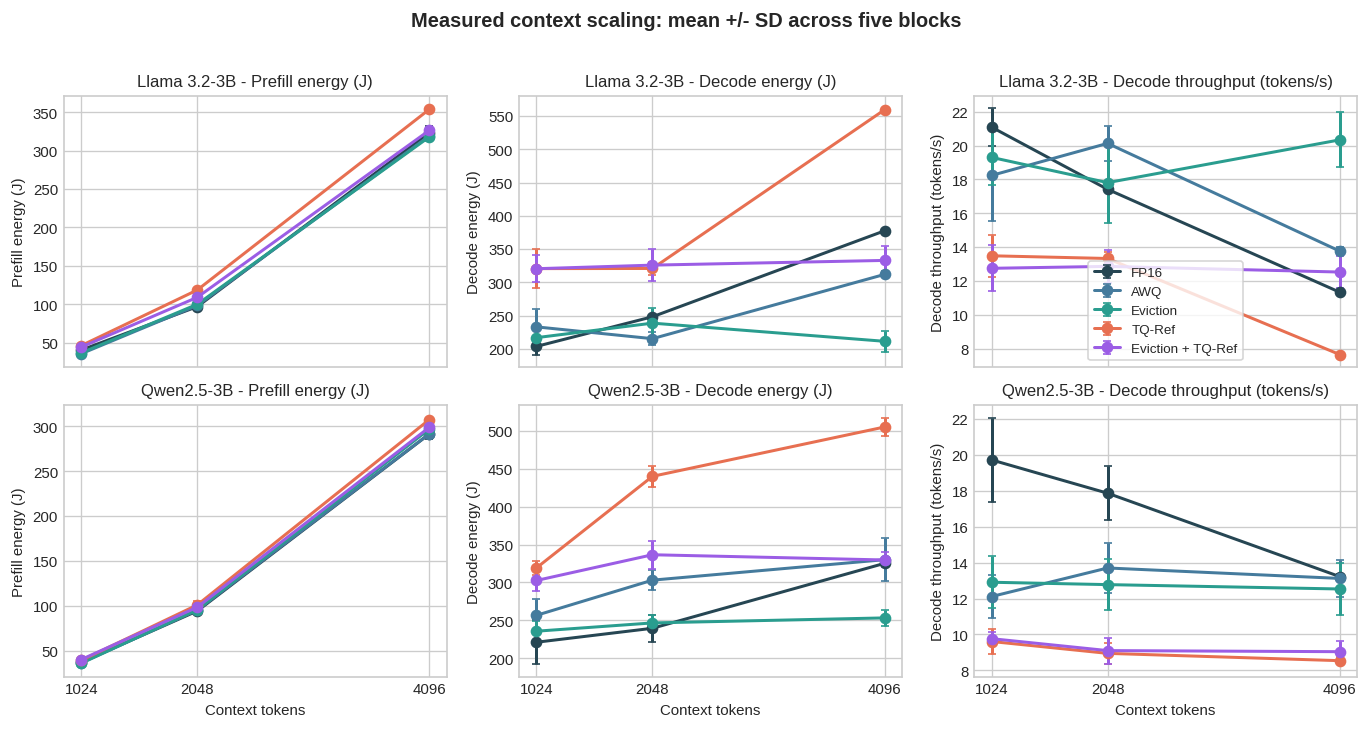

In [7]:
# Run 4A: Figure 2 - measured phase energy and throughput versus context
assert len(core_raw) == 150
assert core_raw.groupby(["model", "source_variant", "context"]).size().eq(5).all()
metrics = [("prefill_energy_j", "Prefill energy (J)"), ("decode_energy_j", "Decode energy (J)"), ("decode_tok_s", "Decode throughput (tokens/s)")]
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.3), sharex=True)
for row, model in enumerate(("llama", "qwen")):
    ordered_variants = list(VARIANT_ROLE[model])
    for col, (metric, ylabel) in enumerate(metrics):
        ax = axes[row, col]
        for variant in ordered_variants:
            role = VARIANT_ROLE[model][variant]
            subset = core_raw[(core_raw.model == model) & (core_raw.source_variant == variant)]
            stats = subset.groupby("context")[metric].agg(["mean", "std"]).reindex([1024, 2048, 4096])
            ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=2.5,
                        linewidth=1.8, color=ROLE_COLORS[role], label=role)
        ax.set_title(f"{MODEL_LABEL[model]} - {ylabel}")
        ax.set_xticks([1024, 2048, 4096])
        ax.set_ylabel(ylabel)
        if row == 1:
            ax.set_xlabel("Context tokens")
        if row == 0 and col == 2:
            ax.legend(loc="best", frameon=True)
fig.suptitle("Measured context scaling: mean +/- SD across five blocks")
save_figure(
    fig,
    "fig02_measured_context_scaling",
    "Measured raw integrations and throughput. Comparisons are within model; software, session, tokenizer, and baseline differences preclude architecture-only causation.",
)

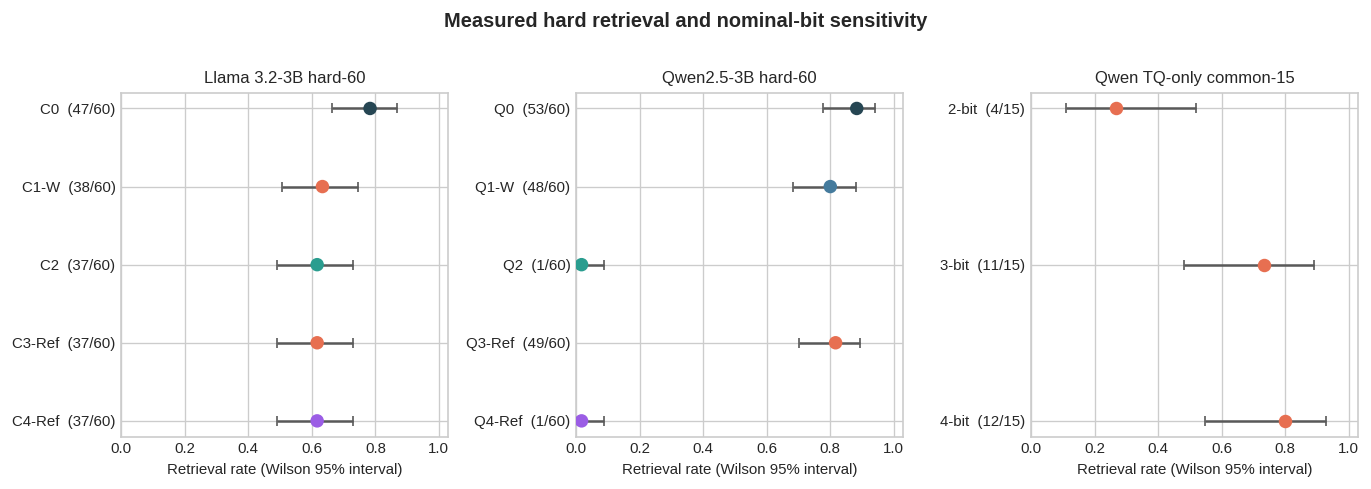

In [8]:
# Run 4B: Figure 3 - hard-retrieval Wilson intervals and Qwen low-bit sensitivity
all_depth = quality[quality["depth"].astype(str).eq("all")].copy()
hard = all_depth[all_depth.quality_population == "hard60"].copy()
common15 = all_depth[all_depth.quality_population == "qwen_common15"].copy()
assert len(hard) == 10 and hard["n"].eq(60).all()
assert len(common15) == 3 and common15["n"].eq(15).all()

fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.2), sharex=True)
for ax, model in zip(axes[:2], ("llama", "qwen")):
    subset = hard[hard.model == model].reset_index(drop=True)
    y = np.arange(len(subset))
    xerr = np.vstack([subset.estimate - subset.wilson95_low, subset.wilson95_high - subset.estimate])
    colors = [ROLE_COLORS[VARIANT_ROLE[model].get(v.replace("-Ref", "") if model == "llama" else v, "TQ-Ref")] for v in subset.source_variant]
    ax.errorbar(subset.estimate, y, xerr=xerr, fmt="none", ecolor="0.35", capsize=3)
    ax.scatter(subset.estimate, y, c=colors, s=50, zorder=3)
    ax.set_yticks(y, [f"{v}  ({k}/{n})" for v, k, n in zip(subset.source_variant, subset.successes, subset.n)])
    ax.set_xlim(0, 1.03)
    ax.set_xlabel("Retrieval rate (Wilson 95% interval)")
    ax.set_title(f"{MODEL_LABEL[model]} hard-60")
    ax.invert_yaxis()

ax = axes[2]
common15 = common15.sort_values("tq_bits").reset_index(drop=True)
y = np.arange(len(common15))
xerr = np.vstack([common15.estimate - common15.wilson95_low, common15.wilson95_high - common15.estimate])
ax.errorbar(common15.estimate, y, xerr=xerr, fmt="none", ecolor="0.35", capsize=3)
ax.scatter(common15.estimate, y, color="#E76F51", s=50, zorder=3)
ax.set_yticks(y, [f"{int(bits)}-bit  ({k}/{n})" for bits, k, n in zip(common15.tq_bits, common15.successes, common15.n)])
ax.set_xlim(0, 1.03)
ax.set_xlabel("Retrieval rate (Wilson 95% interval)")
ax.set_title("Qwen TQ-only common-15")
ax.invert_yaxis()
fig.suptitle("Measured hard retrieval and nominal-bit sensitivity")
save_figure(
    fig,
    "fig03_retrieval_wilson",
    "Hard-60 and Qwen common-15 are separate populations. Ideal quality transfers only under strict output equivalence; Llama low-bit historical quality is excluded.",
)

## Run 5: TurboQuant Realization Gap

The next figures show why the ideal implementation is promising without pretending it was measured. TQ-Ref retains materialized K/V and therefore uses more live cache storage than its matched non-TQ path. The ideal envelope removes materialized K/V and packs indices at the nominal bit width.

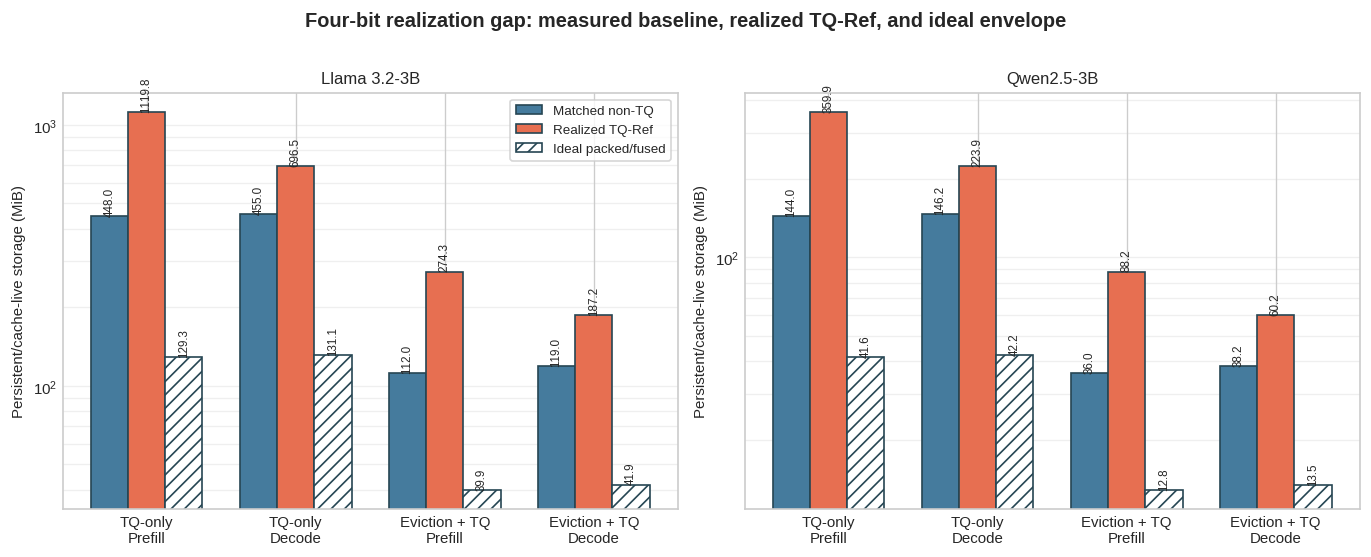

In [9]:
# Run 5A: Figure 4 - measured, realized-reference, and ideal persistent storage
physical_four_bit = {
    "llama_ideal_tq4", "llama_ideal_eviction_tq4",
    "qwen_ideal_tq4", "qwen_ideal_eviction_tq4",
}
storage4 = storage[
    storage.projected_variant.isin(physical_four_bit)
    & storage.nominal_tq_bits.eq(4)
    & storage.phase.isin(["prefill", "decode"])
].copy()
assert len(storage4) == 8
assert np.array_equal(
    storage4.realized_ref_live_bytes - storage4.ideal_aligned_bytes,
    storage4.realized_minus_ideal_bytes,
)
assert np.allclose(storage4.ideal_aligned_bytes / storage4.measured_non_tq_retained_fp_bytes, storage4.ideal_vs_fp_ratio)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, model in zip(axes, ("llama", "qwen")):
    subset = storage4[storage4.model == model].copy()
    subset["path"] = np.where(subset.projected_variant.str.contains("eviction"), "Eviction + TQ", "TQ-only")
    subset["order"] = subset["path"].map({"TQ-only": 0, "Eviction + TQ": 1}) * 2 + subset.phase.map({"prefill": 0, "decode": 1})
    subset = subset.sort_values("order")
    x = np.arange(len(subset))
    width = 0.25
    series = [
        ("Matched non-TQ", "measured_non_tq_live_bytes", "#457B9D", None),
        ("Realized TQ-Ref", "realized_ref_live_bytes", "#E76F51", None),
        ("Ideal packed/fused", "ideal_aligned_bytes", "white", "///"),
    ]
    for offset, (label, column, color, hatch) in zip((-width, 0, width), series):
        values = subset[column] / 2**20
        bars = ax.bar(x + offset, values, width, label=label, color=color, edgecolor="#264653", hatch=hatch)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{value:.1f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(x, [f"{p}\n{phase.title()}" for p, phase in zip(subset.path, subset.phase)])
    ax.set_ylabel("Persistent/cache-live storage (MiB)")
    ax.set_title(MODEL_LABEL[model])
    ax.set_yscale("log")
    ax.grid(axis="y", which="both", alpha=0.3)
    if model == "llama":
        ax.legend(frameon=True)
fig.suptitle("Four-bit realization gap: measured baseline, realized TQ-Ref, and ideal envelope")
save_figure(
    fig,
    "fig04_storage_realization_gap",
    "Ideal bars are analytical persistent-KV allocations, not measured peak VRAM. The Qwen common-15 alias is excluded to avoid duplicating the same physical path.",
)

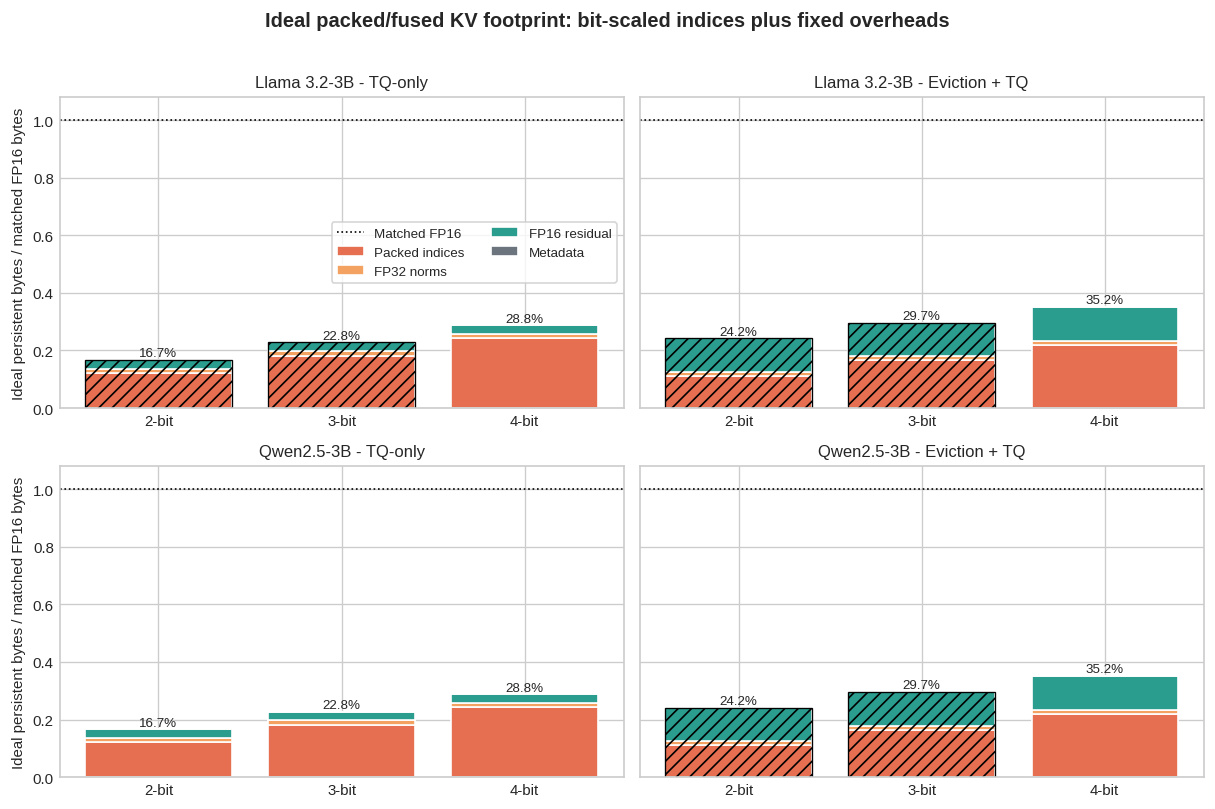

In [10]:
# Run 5B: Figure 5 - ideal packed-KV component scaling across nominal bit widths
ideal_decode = ideal[
    (ideal.context == 4096)
    & (ideal.average_budget == 1024)
    & (ideal.phase == "decode")
    & ideal.nominal_tq_bits.isin([2, 3, 4])
    & ~ideal.projected_variant.eq("qwen_ideal_tq4_common15")
].copy()
assert len(ideal_decode) == 12
component_columns = ["ideal_index_bytes", "ideal_norm_bytes", "ideal_residual_bytes", "ideal_metadata_bytes"]
assert np.array_equal(ideal_decode[component_columns].sum(axis=1), ideal_decode.ideal_logical_bytes)
assert np.allclose(ideal_decode.ideal_aligned_bytes / ideal_decode.fp_logical_bytes, ideal_decode.geometry_normalized_ideal_to_fp_ratio)
for _, group in ideal_decode.groupby(["model", "has_eviction"]):
    ordered = group.sort_values("nominal_tq_bits")
    assert ordered.ideal_aligned_bytes.is_monotonic_increasing

fig, axes = plt.subplots(2, 2, figsize=(10.2, 7.0), sharey=True)
component_style = [
    ("Packed indices", "ideal_index_bytes", "#E76F51"),
    ("FP32 norms", "ideal_norm_bytes", "#F4A261"),
    ("FP16 residual", "ideal_residual_bytes", "#2A9D8F"),
    ("Metadata", "ideal_metadata_bytes", "#6C757D"),
]
for row, model in enumerate(("llama", "qwen")):
    for col, has_eviction in enumerate((False, True)):
        ax = axes[row, col]
        subset = ideal_decode[(ideal_decode.model == model) & (ideal_decode.has_eviction == has_eviction)].sort_values("nominal_tq_bits")
        x = np.arange(len(subset))
        bottom = np.zeros(len(subset))
        for label, column, color in component_style:
            values = subset[column].to_numpy() / subset.fp_logical_bytes.to_numpy()
            ax.bar(x, values, bottom=bottom, color=color, edgecolor="white", label=label)
            bottom += values
        for i, (_, record) in enumerate(subset.iterrows()):
            if not bool(record.quality_energy_pareto_eligible):
                ax.bar(i, record.geometry_normalized_ideal_to_fp_ratio, color="none", edgecolor="black", hatch="///", linewidth=0.8)
            ax.text(i, record.geometry_normalized_ideal_to_fp_ratio + 0.012,
                    f"{100*record.geometry_normalized_ideal_to_fp_ratio:.1f}%", ha="center", fontsize=8)
        ax.axhline(1, color="black", linestyle=":", linewidth=1, label="Matched FP16")
        ax.set_xticks(x, [f"{int(bits)}-bit" for bits in subset.nominal_tq_bits])
        ax.set_ylim(0, 1.08)
        ax.set_title(f"{MODEL_LABEL[model]} - {'Eviction + TQ' if has_eviction else 'TQ-only'}")
        if col == 0:
            ax.set_ylabel("Ideal persistent bytes / matched FP16 bytes")
        if row == 0 and col == 0:
            ax.legend(frameon=True, ncol=2)
fig.suptitle("Ideal packed/fused KV footprint: bit-scaled indices plus fixed overheads")
save_figure(
    fig,
    "fig05_ideal_packed_components",
    "All rows prove lower persistent-KV storage than matched FP16 under the declared layout. Hatched outlines are storage-only paths without eligible hard-quality/energy projection.",
)

## Run 6: Modeled Dataflow and Symbolic Energy Break-Even

The byte-demand model counts algorithmic compulsory reads and writes under the declared fused-reconstruction dataflow. It is not measured DRAM traffic. Ideal energy remains:

\[
E_{ideal}=E_{baseline}-\epsilon_{mem}\Delta D+O_{net}
\]

The figure therefore shows only the identified break-even boundary \(O_{net}/\epsilon_{mem}<\Delta D\), not fabricated ideal joules.

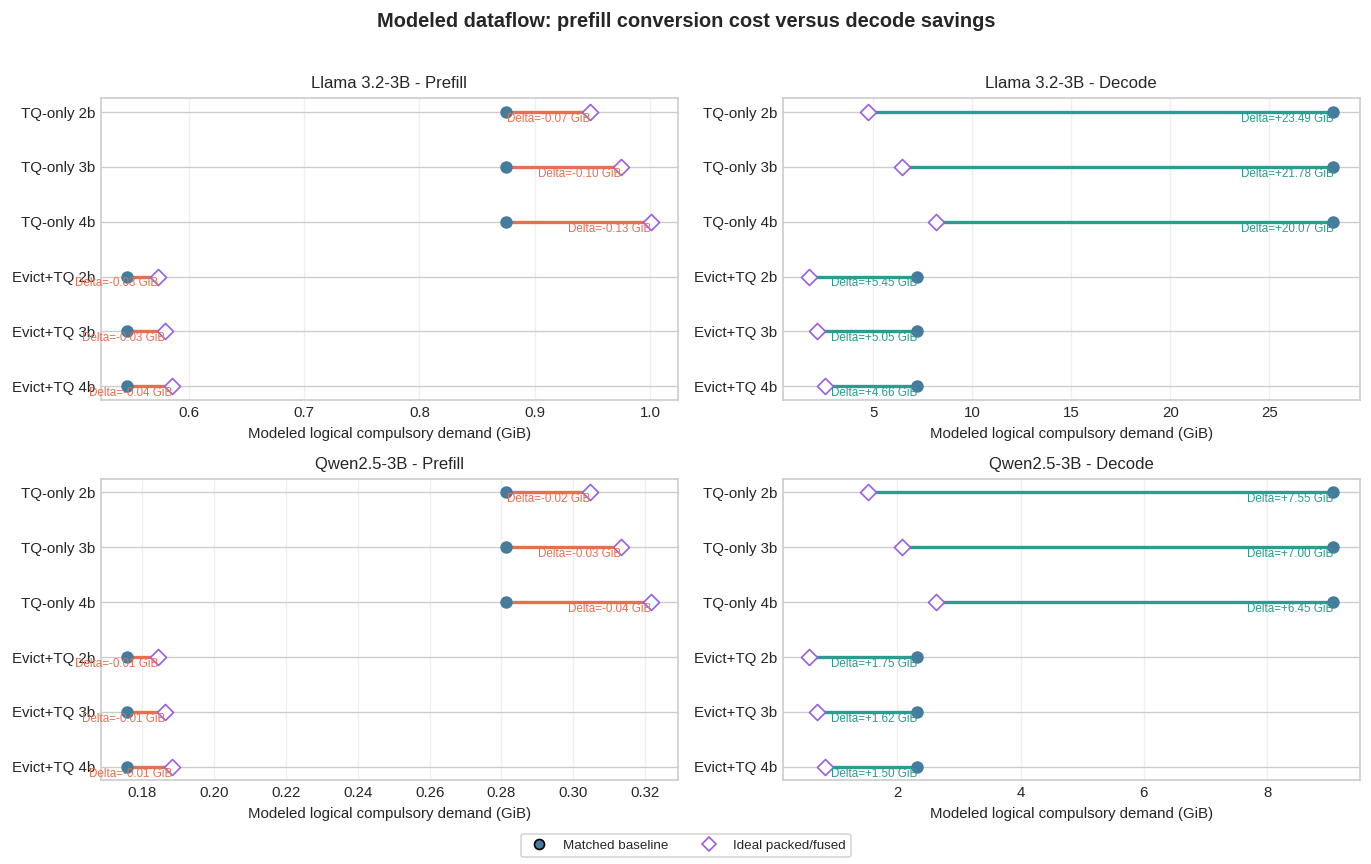

In [11]:
# Run 6A: Figure 6 - modeled prefill/decode logical byte demand
physical_demand = demand[
    ~demand.projected_variant.eq("qwen_ideal_tq4_common15")
    & demand.phase.isin(["prefill", "decode"])
    & demand.nominal_tq_bits.isin([2, 3, 4])
].copy()
assert len(physical_demand) == 24
assert physical_demand.hardware_dram_traffic_identified.astype(str).str.lower().eq("false").all()
assert physical_demand.phase_model_passed.astype(str).str.lower().eq("true").all()
assert np.array_equal(
    physical_demand.baseline_total_modeled_bytes - physical_demand.ideal_total_modeled_bytes,
    physical_demand.delta_d_bytes_for_row,
)
assert (physical_demand[physical_demand.phase == "prefill"].delta_d_bytes_for_row < 0).all()
assert (physical_demand[physical_demand.phase == "decode"].delta_d_bytes_for_row > 0).all()

def demand_label(record):
    path = "Evict+TQ" if "eviction" in record.projected_variant else "TQ-only"
    return f"{path} {int(record.nominal_tq_bits)}b"

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.2))
for row, model in enumerate(("llama", "qwen")):
    for col, phase in enumerate(("prefill", "decode")):
        ax = axes[row, col]
        subset = physical_demand[(physical_demand.model == model) & (physical_demand.phase == phase)].copy()
        subset["eviction_order"] = subset.projected_variant.str.contains("eviction").astype(int)
        subset = subset.sort_values(["eviction_order", "nominal_tq_bits"]).reset_index(drop=True)
        y = np.arange(len(subset))
        baseline_gib = subset.baseline_total_modeled_bytes / 2**30
        ideal_gib = subset.ideal_total_modeled_bytes / 2**30
        for i, (base, projected, delta) in enumerate(zip(baseline_gib, ideal_gib, subset.delta_d_bytes_for_row / 2**30)):
            color = "#2A9D8F" if delta > 0 else "#E76F51"
            ax.plot([base, projected], [i, i], color=color, linewidth=2)
            ax.scatter(base, i, color="#457B9D", s=42, zorder=3)
            ax.scatter(projected, i, facecolor="white", edgecolor="#9B5DE5", marker="D", s=46, zorder=3)
            ax.text(max(base, projected), i + 0.18, f"Delta={delta:+.2f} GiB", ha="right", fontsize=7, color=color)
        ax.set_yticks(y, [demand_label(record) for _, record in subset.iterrows()])
        ax.invert_yaxis()
        ax.set_xlabel("Modeled logical compulsory demand (GiB)")
        ax.set_title(f"{MODEL_LABEL[model]} - {phase.title()}")
        ax.grid(axis="x", alpha=0.3)
fig.suptitle("Modeled dataflow: prefill conversion cost versus decode savings")
handles = [
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor="#457B9D", label="Matched baseline"),
    plt.Line2D([0], [0], marker="D", color="none", markeredgecolor="#9B5DE5", markerfacecolor="white", label="Ideal packed/fused"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=True)
save_figure(
    fig,
    "fig06_modeled_phase_byte_demand",
    "Logical compulsory demand, not measured DRAM traffic. Negative prefill Delta means conversion adds demand; positive decode Delta means modeled demand is avoided.",
)

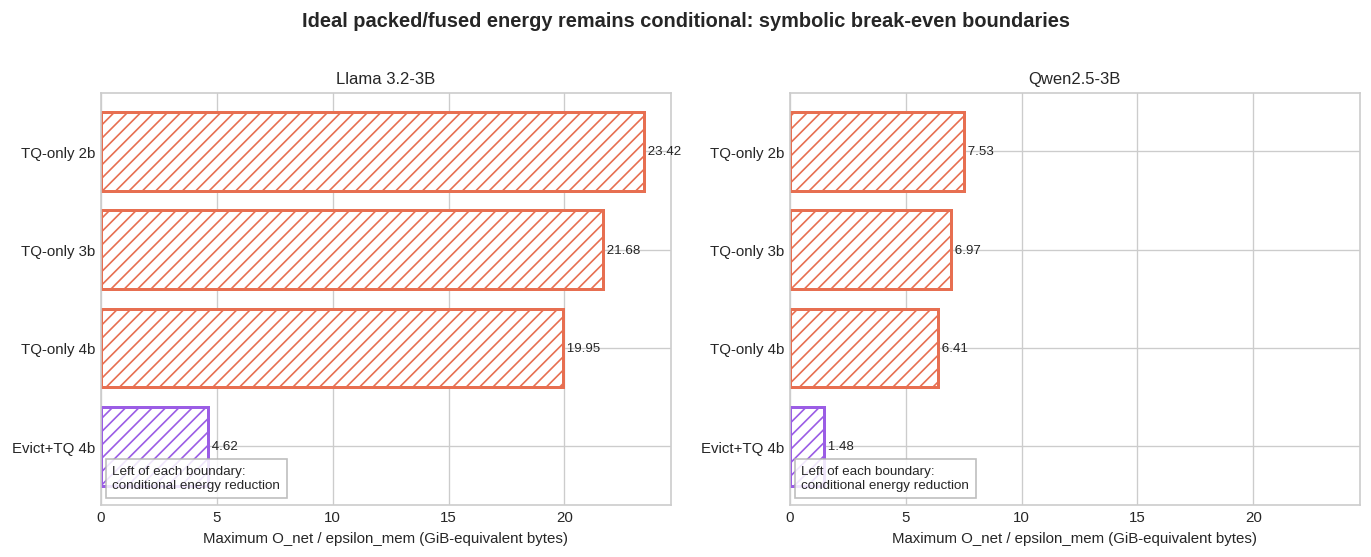

In [12]:
# Run 6B: Figure 7 - parameter-free ideal-energy break-even boundaries
symbolic = break_even[
    (break_even.regime == "raw")
    & (break_even.phase == "total")
    & ~break_even.projected_variant.eq("qwen_ideal_tq4_common15")
    & break_even.break_even_available.astype(str).str.lower().eq("true")
].copy()
assert len(symbolic) == 8
assert (symbolic.delta_d_bytes > 0).all()
assert symbolic.numerical_parameter_domain_declared.astype(str).str.lower().eq("false").all()
assert symbolic.numerical_ideal_energy_j.isna().all()
assert symbolic.numerical_pareto_eligible.astype(str).str.lower().eq("false").all()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharex=True)
for ax, model in zip(axes, ("llama", "qwen")):
    subset = symbolic[symbolic.model == model].copy()
    subset["eviction_order"] = subset.projected_variant.str.contains("eviction").astype(int)
    subset = subset.sort_values(["eviction_order", "nominal_tq_bits"]).reset_index(drop=True)
    y = np.arange(len(subset))
    boundary = subset.delta_d_bytes / 2**30
    colors = np.where(subset.projected_variant.str.contains("eviction"), "#9B5DE5", "#E76F51")
    bars = ax.barh(y, boundary, color="white", edgecolor=colors, hatch="///", linewidth=1.8)
    ax.set_yticks(y, [demand_label(record) for _, record in subset.iterrows()])
    ax.invert_yaxis()
    ax.set_xlabel("Maximum O_net / epsilon_mem (GiB-equivalent bytes)")
    ax.set_title(MODEL_LABEL[model])
    for bar, value in zip(bars, boundary):
        ax.text(value, bar.get_y() + bar.get_height()/2, f" {value:.2f}", va="center", fontsize=8)
    ax.text(0.02, 0.04, "Left of each boundary:\nconditional energy reduction",
            transform=ax.transAxes, fontsize=8, bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "0.7"})
fig.suptitle("Ideal packed/fused energy remains conditional: symbolic break-even boundaries")
save_figure(
    fig,
    "fig07_symbolic_energy_break_even",
    "For epsilon_mem > 0, ideal total energy is lower only when O_net/epsilon_mem is below the plotted Delta_D boundary and energy remains nonnegative. No numerical epsilon_mem, O_net, or ideal joules are assigned.",
)

symbolic[["model", "projected_variant", "nominal_tq_bits", "baseline_variant", "baseline_energy_mean_j", "delta_d_bytes", "ideal_energy_expression", "break_even_o_net_expression"]].to_csv(
    OUTPUT_ROOT / "symbolic_break_even_boundaries.csv", index=False
)

## Run 7: Measured Energy-Quality-Memory Frontier

This final analytical figure uses measured systems only. Energy uncertainty is block SD, quality uncertainty is Wilson 95%, marker area encodes persistent KV storage, and edge weight reflects bootstrap frontier-selection stability rather than a probability of truth.

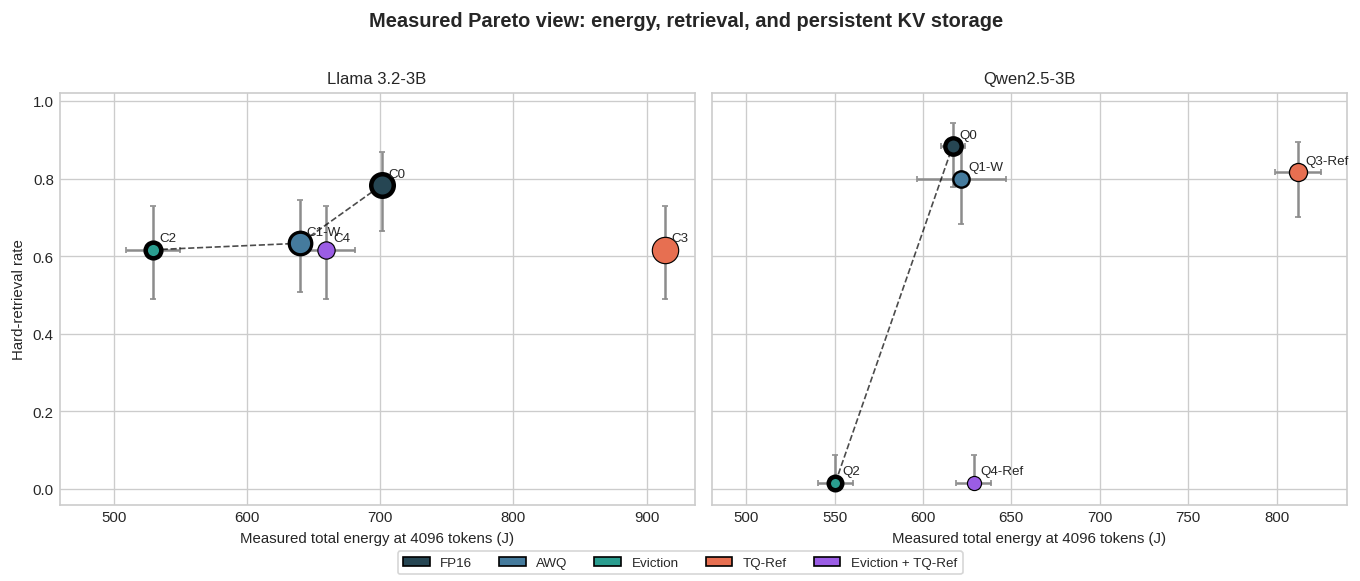

In [13]:
# Run 7: Figure 8 - measured energy-quality-memory Pareto view
assert len(empirical_pareto) == 10
assert empirical_pareto.evidence_tier.eq("measured_system").all()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True)
for ax, model in zip(axes, ("llama", "qwen")):
    subset = empirical_pareto[empirical_pareto.model == model].copy()
    for _, record in subset.iterrows():
        role = {
            "fp16": "FP16", "awq_wrapper": "AWQ", "awq_eviction": "Eviction",
            "awq_tq_ref": "TQ-Ref", "awq_eviction_tq_ref": "Eviction + TQ-Ref",
        }[record.normalized_role]
        yerr = np.array([[record.retrieval_estimate - record.retrieval_wilson_low],
                         [record.retrieval_wilson_high - record.retrieval_estimate]])
        size = 55 + 0.28 * (record.persistent_kv_bytes_mean / 2**20)
        ax.errorbar(record.energy_mean_j, record.retrieval_estimate,
                    xerr=record.energy_sd_j, yerr=yerr, fmt="none", ecolor="0.55", capsize=2, zorder=1)
        ax.scatter(record.energy_mean_j, record.retrieval_estimate, s=size,
                   color=ROLE_COLORS[role], edgecolor="black",
                   linewidth=0.7 + 2.0 * record.bootstrap_frontier_membership_frequency, zorder=3)
        ax.annotate(record.source_variant, (record.energy_mean_j, record.retrieval_estimate),
                    xytext=(4, 5), textcoords="offset points", fontsize=8)
    frontier = subset[subset.point_frontier_member.astype(str).str.lower().eq("true")].sort_values("energy_mean_j")
    ax.plot(frontier.energy_mean_j, frontier.retrieval_estimate, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_title(MODEL_LABEL[model])
    ax.set_xlabel("Measured total energy at 4096 tokens (J)")
    ax.set_xlim(left=max(0, subset.energy_mean_j.min() - 70))
    if model == "llama":
        ax.set_ylabel("Hard-retrieval rate")
    ax.set_ylim(-0.04, 1.02)
fig.suptitle("Measured Pareto view: energy, retrieval, and persistent KV storage")
legend_handles = [Patch(facecolor=color, edgecolor="black", label=role) for role, color in ROLE_COLORS.items()]
fig.legend(handles=legend_handles, loc="lower center", ncol=5, frameon=True)
save_figure(
    fig,
    "fig08_measured_pareto_energy_quality_memory",
    "Measured points only. Marker area encodes persistent KV MiB; edge width encodes bootstrap frontier-selection frequency, which is resampling stability rather than truth probability.",
)

## Run 8: Findings, Provenance, and Downloadable Bundle

The notebook writes figure captions, reusable summary metrics, an output hash manifest, and a final integrity marker. The source synthesis directory is re-hashed to prove it was not modified.

In [14]:
# Run 8: Export reusable findings, manifests, final integrity, and ZIP
from datetime import datetime, timezone
from IPython.display import FileLink, display

assert len(FIGURES) == 8

summary_metrics = {
    "source_fingerprint": integrity["fingerprint"],
    "measured_tq_overhead_4096_total_pct": {},
    "four_bit_decode_storage": {},
    "ideal_energy_identification": {
        "equation": "E_ideal = E_baseline - epsilon_mem * Delta_D + O_net",
        "numerical_parameter_domain_declared": False,
        "numerical_ideal_energy_available": False,
    },
}
for model in ("llama", "qwen"):
    for pair in ("TQ-only", "Eviction + TQ"):
        value = overhead[(overhead.model == model) & (overhead.pair == pair) & (overhead.context == 4096) & (overhead.phase == "Total")].overhead_pct.mean()
        summary_metrics["measured_tq_overhead_4096_total_pct"][f"{model}_{pair.lower().replace(' ', '_').replace('+', 'plus')}"] = float(value)
    row = storage4[(storage4.model == model) & ~storage4.projected_variant.str.contains("eviction") & (storage4.phase == "decode")].iloc[0]
    summary_metrics["four_bit_decode_storage"][model] = {
        "matched_non_tq_mib": float(row.measured_non_tq_live_bytes / 2**20),
        "realized_tq_ref_mib": float(row.realized_ref_live_bytes / 2**20),
        "ideal_packed_mib": float(row.ideal_aligned_bytes / 2**20),
        "ideal_vs_matched_fp_ratio": float(row.ideal_vs_fp_ratio),
        "ideal_vs_realized_ratio": float(row.ideal_aligned_bytes / row.realized_ref_live_bytes),
    }

(OUTPUT_ROOT / "visualization_metrics.json").write_text(json.dumps(summary_metrics, indent=2) + "\n", encoding="utf-8")
protocol = {
    "schema": "cse407-cross-model-visualization-v1-2026-08-07-1",
    "source_bundle": "CSE407_cross_model_synthesis_local_provisional",
    "source_fingerprint": integrity["fingerprint"],
    "input_acquisition": "public Google Drive file downloaded with gdown; no Drive mount",
    "evidence_status": "derived from provisional synthesis; does not promote source evidence",
    "figure_count": len(FIGURES),
    "figure_stems": [item["stem"] for item in FIGURES],
    "ideal_claim_boundary": "ideal persistent-KV and logical byte-demand envelope only; numerical ideal energy, latency, throughput, power, and peak VRAM are unidentified",
}
(OUTPUT_ROOT / "visualization_protocol.json").write_text(json.dumps(protocol, indent=2) + "\n", encoding="utf-8")

llama_tq = summary_metrics["measured_tq_overhead_4096_total_pct"]["llama_tq-only"]
qwen_tq = summary_metrics["measured_tq_overhead_4096_total_pct"]["qwen_tq-only"]
llama_storage = summary_metrics["four_bit_decode_storage"]["llama"]
qwen_storage = summary_metrics["four_bit_decode_storage"]["qwen"]
findings = f"""# Cross-Model Visualization Findings

## Provenance

- Source: provisional synthesis bundle, fingerprint `{integrity['fingerprint']}`.
- Acquisition: public ZIP via `gdown`; no Google Drive mount.
- This visualization does not promote provisional synthesis to accepted evidence.

## Measured TQ-Ref

- At 4096 tokens, measured TQ-only total-energy overhead was {llama_tq:.1f}% for Llama and {qwen_tq:.1f}% for Qwen relative to their registered energy baselines.
- These values describe the numerically active, materialized-K/V, uint8-indexed, unfused TQ-Ref path. They are not packed-kernel overhead estimates.
- The Llama stock-C1 TQ-only comparison remains wrapper-confounded; Qwen uses matched Q1-W.

## Ideal Packed/Fused Envelope

- Llama four-bit decode persistent storage: {llama_storage['matched_non_tq_mib']:.1f} MiB matched non-TQ, {llama_storage['realized_tq_ref_mib']:.1f} MiB realized TQ-Ref, and {llama_storage['ideal_packed_mib']:.1f} MiB ideal packed.
- Qwen four-bit decode persistent storage: {qwen_storage['matched_non_tq_mib']:.1f} MiB matched non-TQ, {qwen_storage['realized_tq_ref_mib']:.1f} MiB realized TQ-Ref, and {qwen_storage['ideal_packed_mib']:.1f} MiB ideal packed.
- The ideal four-bit TQ-only envelope is about {100*llama_storage['ideal_vs_matched_fp_ratio']:.1f}% of matched FP16 persistent KV for both geometries under the declared residual/norm layout.
- This supports a persistent-memory advantage, not a measured total-VRAM, latency, energy, throughput, or power advantage.

## Conditional Energy

- Ideal energy remains `E_ideal = E_baseline - epsilon_mem * Delta_D + O_net`.
- Prefill conversion adds modeled logical demand, while the fixed 64-token decode avoids substantially more demand under fused reconstruction.
- Numerical ideal joules are intentionally absent because `epsilon_mem` and `O_net` have no justified measured domains.

## Reuse

- Reuse the plotting structure with explicit per-model variant maps, immutable input fingerprints, separate quality populations, and evidence-tier styling.
- For a new model, regenerate the normalized synthesis tables first; do not relabel another model's ideal storage or quality path.
"""
(OUTPUT_ROOT / "visualization_findings.md").write_text(findings, encoding="utf-8")

current_source = {
    str(path.relative_to(SOURCE)): sha256_file(path)
    for path in sorted(SOURCE.rglob("*")) if path.is_file()
}
assert current_source == SOURCE_SNAPSHOT

pre_manifest_files = sorted(path for path in OUTPUT_ROOT.iterdir() if path.is_file())
output_items = [{"path": path.name, "bytes": path.stat().st_size, "sha256": sha256_file(path)} for path in pre_manifest_files]
manifest_payload = {"schema": protocol["schema"], "source_fingerprint": integrity["fingerprint"], "files": output_items}
(OUTPUT_ROOT / "visualization_output_manifest.json").write_text(json.dumps(manifest_payload, indent=2) + "\n", encoding="utf-8")
visualization_fingerprint = hashlib.sha256(json.dumps(manifest_payload, sort_keys=True, separators=(",", ":")).encode()).hexdigest()[:16]
final = {
    "schema": protocol["schema"],
    "passed": True,
    "visualization_fingerprint": visualization_fingerprint,
    "source_fingerprint": integrity["fingerprint"],
    "source_unchanged": True,
    "figures": len(FIGURES),
    "figure_files": len(FIGURES) * 2,
    "output_files_before_final_integrity": len(list(OUTPUT_ROOT.iterdir())),
    "ideal_numerical_energy_claimed": False,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_ROOT / "final_integrity.json").write_text(json.dumps(final, indent=2) + "\n", encoding="utf-8")

archive_path = Path(shutil.make_archive("/content/CSE407_cross_model_visualization_v1", "zip", root_dir=OUTPUT_ROOT))
archive_sha256 = sha256_file(archive_path)
print(json.dumps({**final, "archive": str(archive_path), "archive_sha256": archive_sha256}, indent=2))
display(FileLink(str(archive_path)))

{
  "schema": "cse407-cross-model-visualization-v1-2026-08-07-1",
  "passed": true,
  "visualization_fingerprint": "53ead4e6db45d2a8",
  "source_fingerprint": "b19adce0924b4203",
  "source_unchanged": true,
  "figures": 8,
  "figure_files": 16,
  "output_files_before_final_integrity": 22,
  "ideal_numerical_energy_claimed": false,
  "completed_at_utc": "2026-08-07T07:42:58.954090+00:00",
  "archive": "/content/CSE407_cross_model_visualization_v1.zip",
  "archive_sha256": "e718e64193f2b162f674d87d5654935ba1f879fa5064243e4e30c3493ae0eb88"
}


/content/CSE407_cross_model_visualization_v1.zip